In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
path = "Analytical/"
dfSale = pd.read_csv(path + "sales.csv" )
dfSale.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3833 entries, 0 to 3832
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Date     3833 non-null   object 
 1   Revenue  3833 non-null   float64
 2   COGS     3833 non-null   float64
dtypes: float64(2), object(1)
memory usage: 90.0+ KB


# **Giải thích các cột dữ liệu**

| Column   | Data Type | Description                     |
|----------|----------|---------------------------------|
| Date     | Date     | Ngày tháng                     |
| Revenue  | Float    | Tổng doanh thu thuần           |
| COGS     | Float    | Tổng giá vốn hàng bán          |


Gross Profit = Revenue - COGS

In [4]:
(dfSale.head())

,Date,Revenue,COGS
0,2012-07-04,5123547.94,3982991.19
1,2012-07-05,2751773.45,2150580.23
2,2012-07-06,3054029.42,2517632.84
3,2012-07-07,2667930.94,2108246.62
4,2012-07-08,2360851.90,1808622.79


In [5]:
dfSale.tail()

,Date,Revenue,COGS
3828,2022-12-27,2100553.66,2184872.24
3829,2022-12-28,3448729.20,3513621.00
3830,2022-12-29,3083944.33,3170787.10
3831,2022-12-30,2884668.76,3022292.15
3832,2022-12-31,2383037.48,2279288.13


In [6]:

print('\n--- Missing Values ---')
print(dfSale.isnull().sum())

print('\n--- Duplicate Rows ---')
duplicate_count = dfSale.duplicated().sum()
print(f'Number of duplicate rows: {duplicate_count}')

print('\n--- Statistical Summary ---')
display(dfSale.describe())


--- Missing Values ---
Date       0
Revenue    0
COGS       0
dtype: int64

--- Duplicate Rows ---
Number of duplicate rows: 0

--- Statistical Summary ---


,Revenue,COGS
count,3.833000e+03,3.833000e+03
mean,4.286584e+06,3.695134e+06
std,2.624840e+06,2.219789e+06
min,2.798139e+05,2.365763e+05
25%,2.471089e+06,2.150580e+06
50%,3.647304e+06,3.161113e+06
75%,5.350877e+06,4.637294e+06
max,2.090527e+07,1.653586e+07


In [7]:
dfSale["Date"] =  pd.to_datetime(dfSale['Date'])

In [8]:
df_copy = dfSale.copy()
(df_copy['COGS'] > df_copy['Revenue']).sum()

382

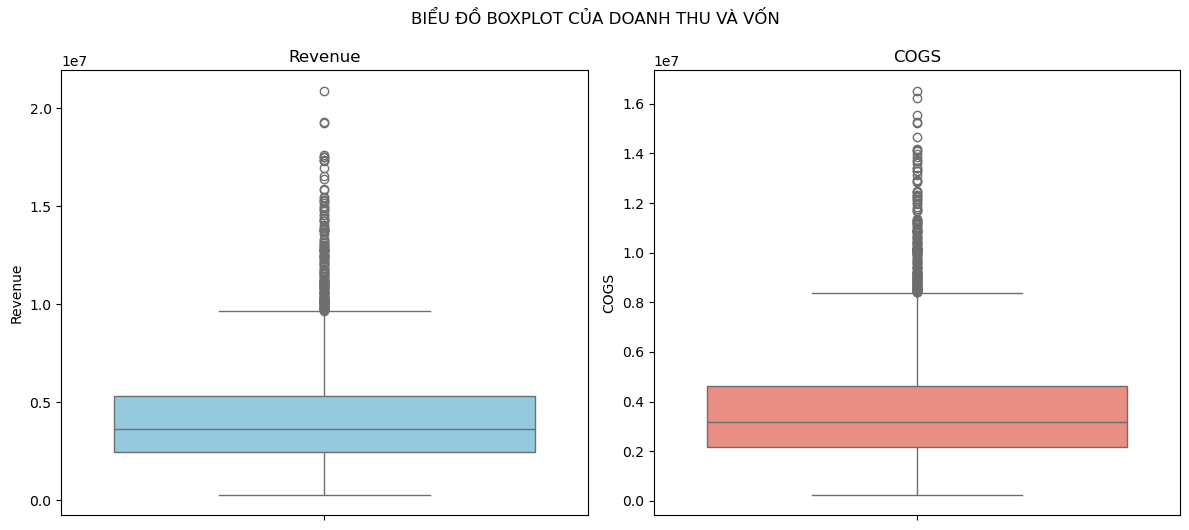

In [9]:
# Tìm outlies
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.boxplot(y=df_copy['Revenue'], color='skyblue')
plt.title('Revenue')

plt.subplot(1, 2, 2)
sns.boxplot(y=df_copy['COGS'], color='salmon')
plt.title('COGS')

plt.tight_layout()
plt.suptitle("BIỂU ĐỒ BOXPLOT CỦA DOANH THU VÀ VỐN", y=1.05)
plt.show()

In [10]:
def count_outliers(series):
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    return ((series < lower_bound) | (series > upper_bound)).sum()

revenue_outliers = count_outliers(df_copy['Revenue'])
cogs_outliers = count_outliers(df_copy['COGS'])

print(f'Số lượng outliers trong Revenue: {revenue_outliers}')
print(f'Số lượng outliers trong COGS: {cogs_outliers}')

Số lượng outliers trong Revenue: 169
Số lượng outliers trong COGS: 165


**Nhận xét về Outliers:**
- **Số lượng:**
    - **169 outliers** trong doanh thu (`Revenue`)
    - **165 outliers** trong giá vốn (`COGS`).
- **Phân bố ouliers:**
    - Vì số lượng outliers chiếm khoảng **4-5%** tổng dữ liệu

In [12]:
# 1. Kiểm tra phạm vi thời gian
min_date = df_copy['Date'].min()
max_date = df_copy['Date'].max()
print(f"Dữ liệu từ ngày: {min_date} đến ngày: {max_date}")

# 2. Kiểm tra các ngày bị thiếu (gaps)
full_range = pd.date_range(start=min_date, end=max_date, freq='D')
missing_days = full_range.difference(df_copy['Date'])
print(f"Số lượng ngày bị thiếu trong chuỗi thời gian: {len(missing_days)}")

# 3. Tạo các đặc trưng thời gian
df_copy['Year'] = df_copy['Date'].dt.year
df_copy['Month'] = df_copy['Date'].dt.month
df_copy['DayOfWeek'] = df_copy['Date'].dt.dayofweek # 0=Monday, 6=Sunday
df_copy['IsWeekend'] = df_copy['DayOfWeek'].isin([5, 6]).astype(int)

display(df_copy.head())

Dữ liệu từ ngày: 2012-07-04 00:00:00 đến ngày: 2022-12-31 00:00:00
Số lượng ngày bị thiếu trong chuỗi thời gian: 0


,Date,Revenue,COGS,Year,Month,DayOfWeek,IsWeekend
0,2012-07-04,5123547.94,3982991.19,2012,7,2,0
1,2012-07-05,2751773.45,2150580.23,2012,7,3,0
2,2012-07-06,3054029.42,2517632.84,2012,7,4,0
3,2012-07-07,2667930.94,2108246.62,2012,7,5,1
4,2012-07-08,2360851.90,1808622.79,2012,7,6,1


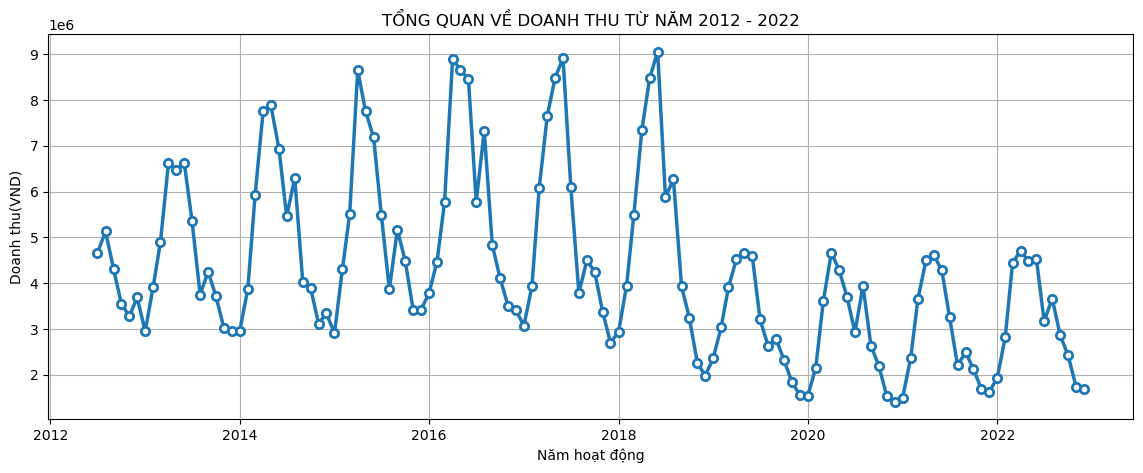

In [13]:
revenuebyyearMonth = df_copy.groupby(["Year",'Month'])[["Revenue"]].mean().reset_index().sort_values(by = ['Year', 'Month'])
revenuebyyearMonth['date'] = pd.to_datetime(revenuebyyearMonth[["Year",'Month']].assign(DAY=1))
revenuebyyearMonth = revenuebyyearMonth.sort_values('date')

plt.figure(figsize=(14, 5))

plt.plot(
    revenuebyyearMonth['date'],
    revenuebyyearMonth['Revenue'],
    linewidth=2.5,
    marker='o',
    markerfacecolor='white',    # Tâm marker màu trắng
    markeredgewidth=2,          # Viền marker
)
plt.title("TỔNG QUAN VỀ DOANH THU TỪ NĂM 2012 - 2022")
plt.xlabel("Năm hoạt động")
plt.ylabel("Doanh thu(VND)")
plt.grid('-.-')
plt.show()

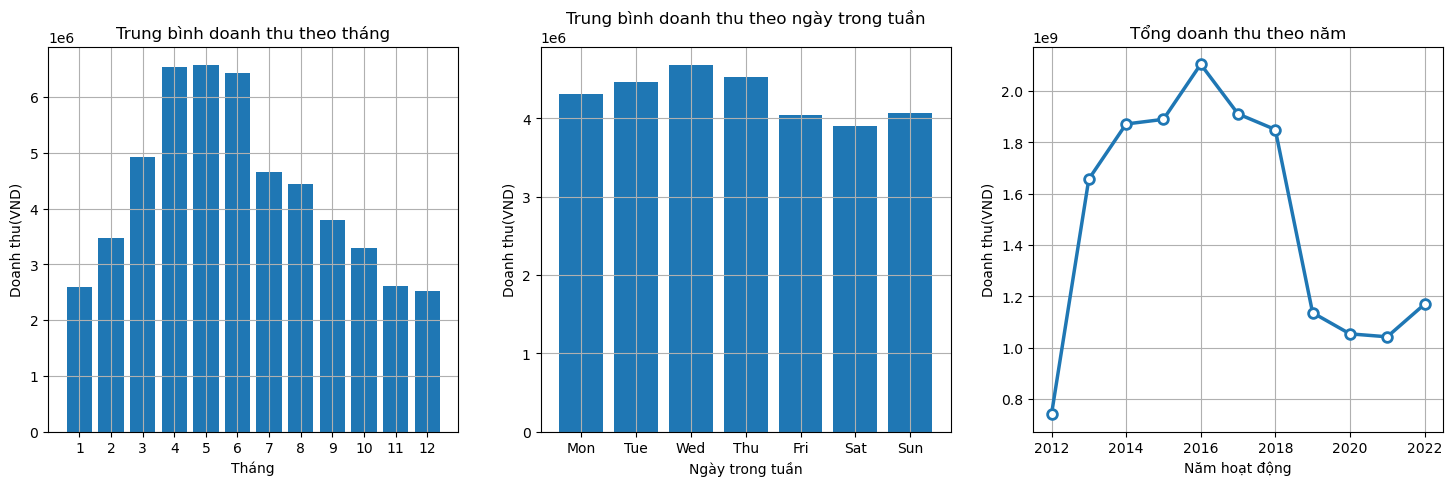

In [14]:
plt.figure(figsize=(18,5))


plt.subplot(1,3,1)
revenueByMonth = df_copy.groupby("Month")["Revenue"].mean().reset_index().sort_values("Month")
plt.bar(
    revenueByMonth["Month"],
    revenueByMonth["Revenue"],
)
plt.xticks(range(1,13))
plt.xlabel("Tháng")
plt.ylabel("Doanh thu(VND)")
plt.grid('--')
plt.title("Trung bình doanh thu theo tháng")


plt.subplot(1,3,2)
revenueByDayOfWeek = df_copy.groupby("DayOfWeek")["Revenue"].mean().reset_index().sort_values("DayOfWeek")
plt.bar(
    revenueByDayOfWeek["DayOfWeek"],
    revenueByDayOfWeek["Revenue"],
)
plt.xticks(ticks=range(7), labels=['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'])
plt.xlabel("Ngày trong tuần")
plt.ylabel("Doanh thu(VND)")
plt.grid('--')
plt.title("Trung bình doanh thu theo ngày trong tuần")

plt.subplot(1,3,3)
revenueByYear = df_copy.groupby("Year")["Revenue"].sum().reset_index().sort_values("Year")
plt.plot(
    revenueByYear["Year"],
    revenueByYear["Revenue"],
    marker = "o",
    linewidth=2.5,
    markersize=7,
    markerfacecolor='white',    # Tâm marker màu trắng
    markeredgewidth=2,   
)
plt.xlabel("Năm hoạt động")
plt.ylabel("Doanh thu(VND)")
plt.grid('--')
plt.title("Tổng doanh thu theo năm")

plt.show()

**Nhận xét về xu hướng Doanh thu (Revenue)**:

Dựa trên các biểu đồ phân tích, chúng ta có các quan sát chi tiết về biến động doanh thu như sau:

1. Tính mùa vụ (Average Revenue by Month)

* **Đỉnh doanh thu:** Doanh thu trung bình đạt mức cao nhất vào các tháng giữa năm, cụ thể là **tháng 4, 5 và 6**. Đây là giai đoạn thị trường hoạt động sôi nổi nhất.
* **Vùng thấp điểm:** Doanh thu có xu hướng giảm dần về cuối năm và đạt mức thấp nhất vào **tháng 12 và tháng 1**.
* **Xu hướng chung:** Biểu đồ có dạng hình chuông ngược nhẹ, tăng trưởng từ đầu năm, đạt đỉnh vào quý 2 và giảm dần vào hai quý cuối năm.

2. Sự ổn định hàng tuần (Average Revenue by Day of Week)

* **Hiệu suất đầu tuần:** Doanh thu duy trì ở mức cao và ổn định từ Thứ 2 đến Thứ 5, trong đó **Thứ 4 (Wed)** ghi nhận mức doanh thu trung bình cao nhất.
* **Sụt giảm cuối tuần:** Có sự sụt giảm rõ rệt về doanh thu vào các ngày cuối tuần (**Thứ 7 và Chủ Nhật**). Điều này cho thấy khách hàng hoặc các giao dịch có xu hướng tập trung vào các ngày làm việc trong tuần hơn là thời gian nghỉ lễ/cuối tuần.

3. Tăng trưởng dài hạn (Total Revenue by Year)

* **Giai đoạn tăng trưởng (2012 - 2016):** Tổng doanh thu có sự bứt phá mạnh mẽ trong 4 năm đầu và đạt đỉnh lịch sử vào năm **2016** (vượt mốc 2.0 tỷ).
* **Giai đoạn suy thoái (2017 - 2021):** Sau khi đạt đỉnh, doanh thu bắt đầu sụt giảm. Đặc biệt từ sau năm 2018, doanh thu giảm sâu và chạm đáy vào khoảng năm **2020 - 2021** (xuống mức gần 1.0 tỷ).
* **Dấu hiệu phục hồi (2022):** Trong năm gần nhất (2022), biểu đồ đã bắt đầu đảo chiều và có tín hiệu **tăng trưởng trở lại**, cho thấy các nỗ lực phục hồi kinh doanh đang có kết quả khả quan.

Số ngày ghi nhận lỗ gộp: 382
Phần trăm ngày bị lỗ: 9.97%


,Date,Revenue,COGS,Year,Month,DayOfWeek,IsWeekend,GrossProfit
392,2013-07-31,10104475.36,10851542.12,2013,7,2,0,-747066.76
393,2013-08-01,10998208.40,12167214.07,2013,8,3,0,-1169005.67
394,2013-08-02,7422715.15,9601836.11,2013,8,4,0,-2179120.96
395,2013-08-03,5599602.67,7786528.35,2013,8,5,1,-2186925.68
396,2013-08-04,5021938.29,7089757.76,2013,8,6,1,-2067819.47


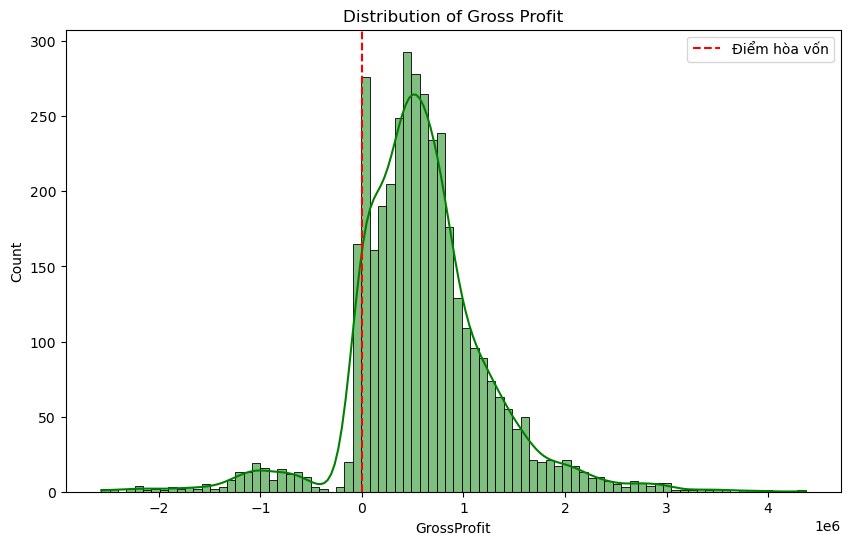

In [16]:
# Tính Gross Profit
df_copy['GrossProfit'] = df_copy['Revenue'] - df_copy['COGS']

# Lọc ra các ngày bị lỗ
loss_days = df_copy[df_copy['GrossProfit'] < 0]

print(f"Số ngày ghi nhận lỗ gộp: {len(loss_days)}")
print(f"Phần trăm ngày bị lỗ: {(len(loss_days)/len(df_copy))*100:.2f}%")

display(loss_days.head())

# Trực quan hóa phân phối Gross Profit
plt.figure(figsize=(10, 6))
sns.histplot(df_copy['GrossProfit'], kde=True, color='green')
plt.axvline(0, color='red', linestyle='--', label='Điểm hòa vốn')
plt.title('Distribution of Gross Profit')
plt.legend()
plt.show()

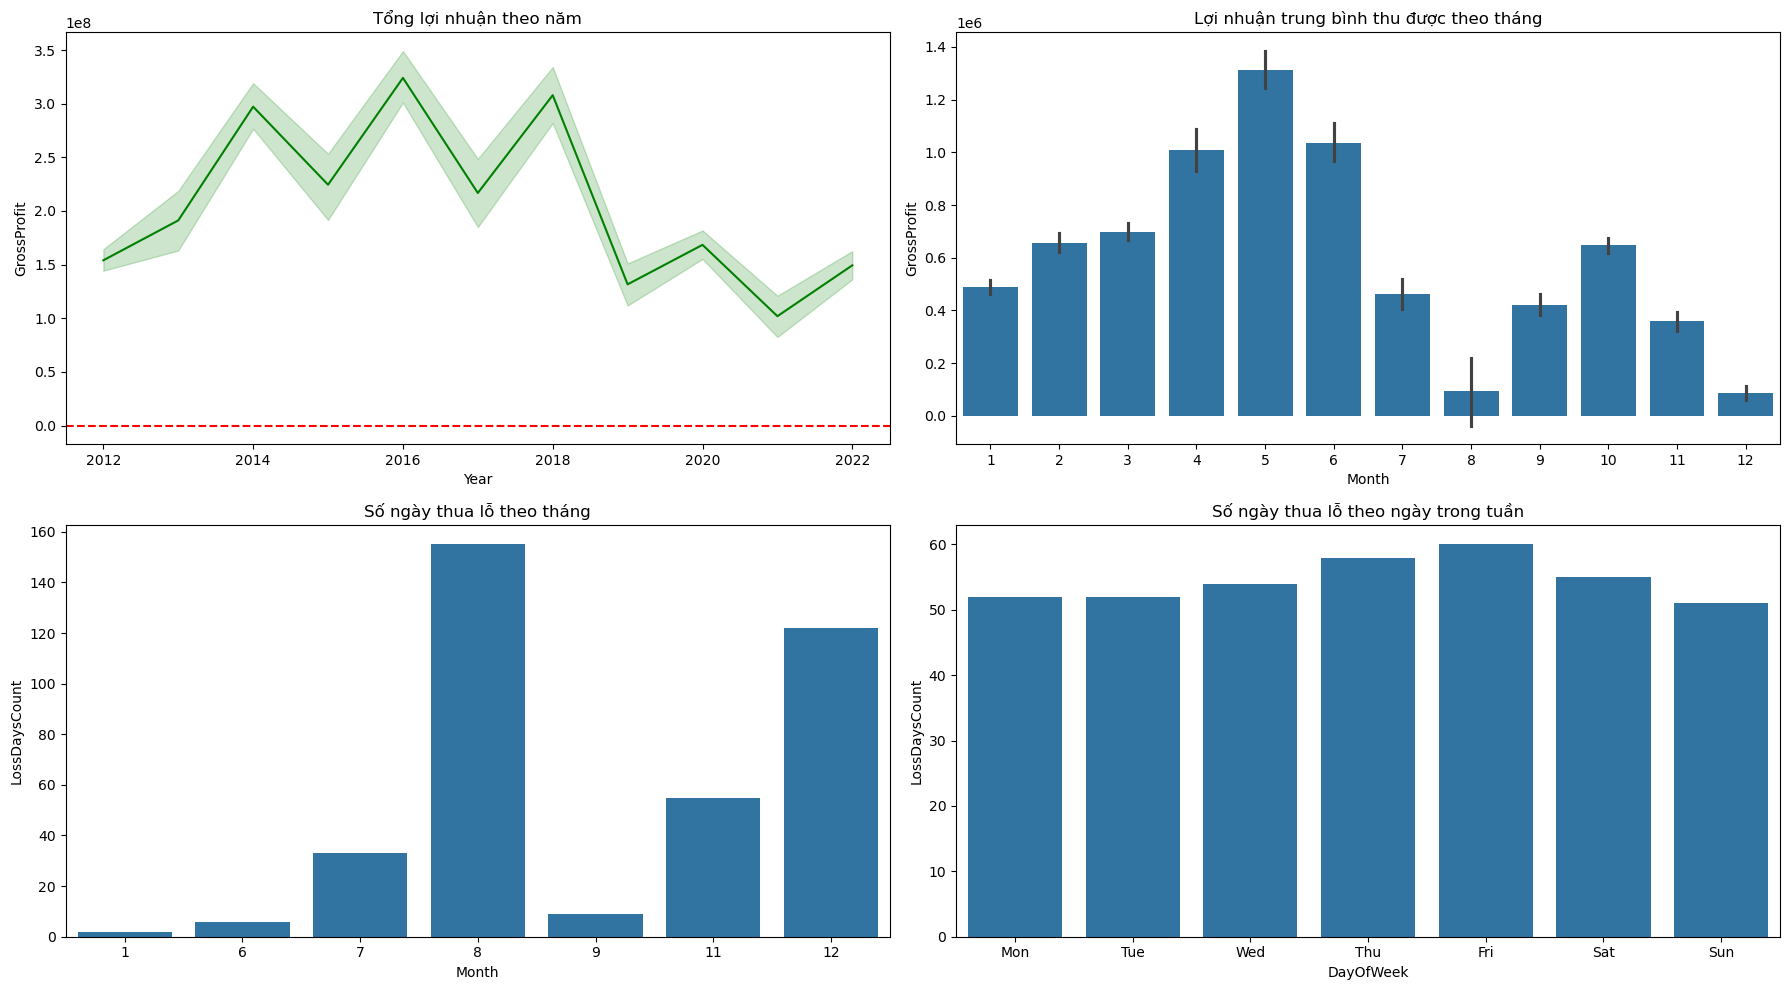

In [17]:
plt.figure(figsize=(18, 10))

# 1. Xu hướng Gross Profit theo thời gian (năm)
plt.subplot(2, 2, 1)
sns.lineplot(x='Year', y='GrossProfit', data=df_copy, estimator='sum', color='green')
plt.axhline(0, color='red', linestyle='--')
plt.title('Tổng lợi nhuận theo năm')

# 2. Gross Profit trung bình theo tháng
plt.subplot(2, 2, 2)
sns.barplot(x='Month', y='GrossProfit', data=df_copy)
plt.title('Lợi nhuận trung bình thu được theo tháng')

# 3. Phân bổ số ngày lỗ theo Tháng
loss_by_month = loss_days.groupby('Month').size().reset_index(name='LossDaysCount')
plt.subplot(2, 2, 3)
sns.barplot(x='Month', y='LossDaysCount', data=loss_by_month)
plt.title('Số ngày thua lỗ theo tháng')

# 4. Phân bổ số ngày lỗ theo Thứ trong tuần
loss_by_dow = loss_days.groupby('DayOfWeek').size().reset_index(name='LossDaysCount')
plt.subplot(2, 2, 4)
sns.barplot(x='DayOfWeek', y='LossDaysCount', data=loss_by_dow)
plt.xticks(ticks=range(7), labels=['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'])
plt.title('Số ngày thua lỗ theo ngày trong tuần')

plt.tight_layout()
plt.show()

**Nhận xét về Gross Profit theo thời gian:**

- **Biến động theo mùa:** Có sự gia tăng đột biến về số ngày lỗ vào **tháng 8** và **tháng 12**. Điều này có thể liên quan đến các chương trình khuyến mãi lớn hoặc chi phí nhập hàng tăng vọt trong các giai đoạn này.
- **Tính ổn định:** Gross Profit theo năm không ổn định, cần kiểm tra xem doanh thu giảm hay COGS tăng trong các giai đoạn lợi nhuận thấp.
- **Ngày trong tuần:** Không có sự khác biệt quá lớn về rủi ro lỗ giữa các ngày trong tuần.

In [19]:
loss_by_year = loss_days.groupby('Year').size().reset_index(name='LossDaysCount')
loss_by_year

,Year,LossDaysCount
0,2013,45
1,2014,13
2,2015,55
3,2016,19
4,2017,47
5,2018,9
6,2019,46
7,2020,23
8,2021,74
9,2022,51


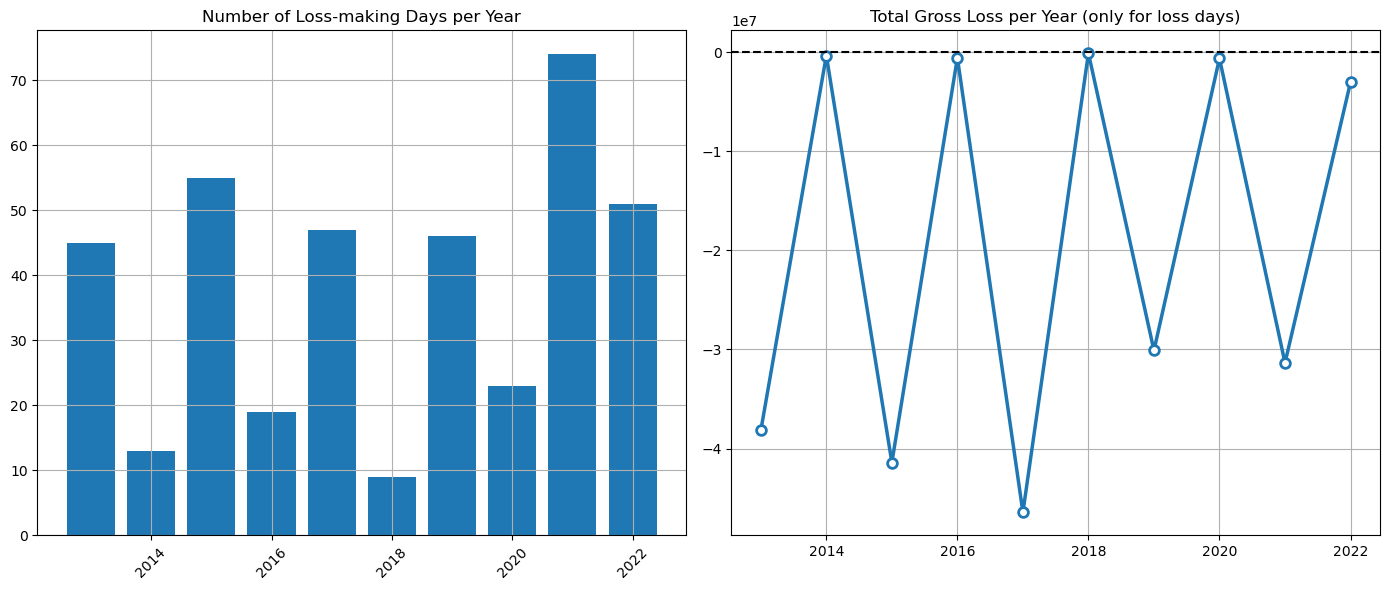

Thống kê số ngày lỗ cụ thể qua từng năm:


,Year,LossDaysCount
0,2013,45
1,2014,13
2,2015,55
3,2016,19
4,2017,47
5,2018,9
6,2019,46
7,2020,23
8,2021,74
9,2022,51


In [20]:
# Thống kê số ngày lỗ theo Năm

# Vẽ biểu đồ
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.bar(loss_by_year["Year"], 
        loss_by_year["LossDaysCount"]
       )
plt.title('Number of Loss-making Days per Year')
plt.xticks(rotation=45)
plt.grid("--")
plt.subplot(1, 2, 2)
loss_daysByYear = loss_days.groupby("Year")["GrossProfit"].sum().reset_index().sort_values("Year")

plt.plot(loss_daysByYear["Year"],
         loss_daysByYear["GrossProfit"], 
         marker = "o",
        linewidth=2.5,
        markersize=7,
        markerfacecolor='white',    # Tâm marker màu trắng
        markeredgewidth=2,  
        )
plt.title('Total Gross Loss per Year (only for loss days)')
plt.axhline(0, color='black', linestyle='--')
plt.grid("--")
plt.tight_layout()
plt.show()

# Hiển thị bảng dữ liệu để soi chi tiết
print("Thống kê số ngày lỗ cụ thể qua từng năm:")
display(loss_by_year.sort_values('Year'))

In [21]:
# Xóa các cột đặc trưng thời gian vừa tạo
df_copy = df_copy.drop(columns=['Year', 'Month', 'DayOfWeek', 'IsWeekend', 'GrossProfit'])

print("Đã xóa các cột Year, Month, DayOfWeek, IsWeekend.")
display(df_copy.head())

Đã xóa các cột Year, Month, DayOfWeek, IsWeekend.


,Date,Revenue,COGS
0,2012-07-04,5123547.94,3982991.19
1,2012-07-05,2751773.45,2150580.23
2,2012-07-06,3054029.42,2517632.84
3,2012-07-07,2667930.94,2108246.62
4,2012-07-08,2360851.90,1808622.79


In [22]:
pathDataCleaned = 'dataCleaned/sale_cleaned.csv'
df_copy.to_csv(pathDataCleaned, index=False)
print(f"Đã lưu file vào Drive thành công: {pathDataCleaned}")

Đã lưu file vào Drive thành công: dataCleaned/sale_cleaned.csv
